In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add the parent directory to Python path so we can import from src
import sys
import os
parent_dir = os.path.dirname(os.getcwd())
sys.path.append(parent_dir)

from src.tree_bstats.balance_index_coefficients import BalanceIndexCoefficients
from src.tree_bstats.clade_basis import clade_mean, clade_cov_matrix
from src.tree_bstats.daughter_basis import daughter_mean, daughter_cov_matrix
from src.tree_bstats.tree import Tree
from src.tree_bstats.unlabelled_tree import UnlabelledTree

In [2]:
from importlib import reload
import src.tree_bstats.balance_index_coefficients
reload(src.tree_bstats.balance_index_coefficients)

<module 'src.tree_bstats.balance_index_coefficients' from 'c:\\Users\\djbau\\OneDrive\\Desktop\\Research\\Stanford\\Rosenberg Lab\\code\\src\\tree_bstats\\balance_index_coefficients.py'>

# Calculate mean of balance indices for small n (up to 18)

We use three methods. The first, stored in array mean, uses the basis representations to calculate the mean. 
The second generates all trees of a given size using the UnlabelledTree class, calculates all the balance indices, and computes the weighted average (with the Yule probability weights) to find the mean of the index under the Yule model.
The last method uses the simplified equations for the mean that we found in Mathematica.  

We observe that these methods generate equivalent results, demonstrating the correctness of the formulas. 

In [11]:
mean = []
max_n = 18
labels = BalanceIndexCoefficients().get_daughter_labels()

# For all n in the range, we will compute the mean of all basis indices under daughter basis
N = range(4, max_n + 1)
for n in N:
    mu = daughter_mean(n)
    daughter_coef = BalanceIndexCoefficients(n).get_daughter_coefficients()
    matrix_of_coef= np.array(list(daughter_coef.values()))

    mean.append(np.dot(matrix_of_coef, mu))

mean = np.array(mean)

In [ ]:
# Instead, we can also compute the means explicitly using all the trees of a given size
max_n = 18
all_trees = UnlabelledTree(max_n)

mean_all_trees = []

for n in np.arange(4, max_n + 1):
    _, _, balance_indices, weights = all_trees.get_data(n)
    balance_indices = np.array(balance_indices)
    unlabelledTreeLabels = all_trees.balance_index_names
    n_means = np.zeros((len(labels),))
    for i, label in enumerate(labels):
        correct_col = unlabelledTreeLabels.index(label)
        mean_stat = np.sum(balance_indices[:, correct_col] * weights) / np.sum(weights)
        n_means[i] = mean_stat
    mean_all_trees.append(n_means)
mean_all_trees = np.array(mean_all_trees)

   

Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905, 24631, 56011]


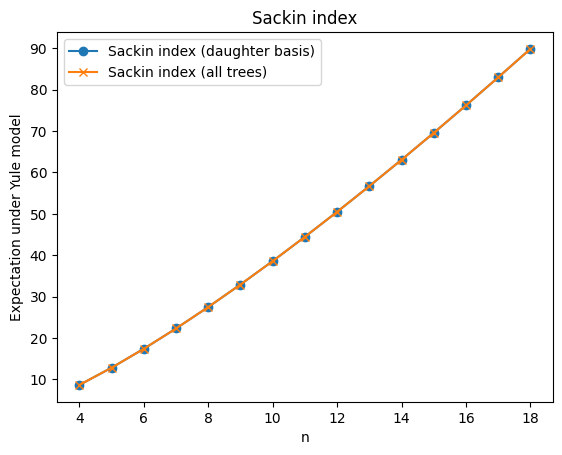

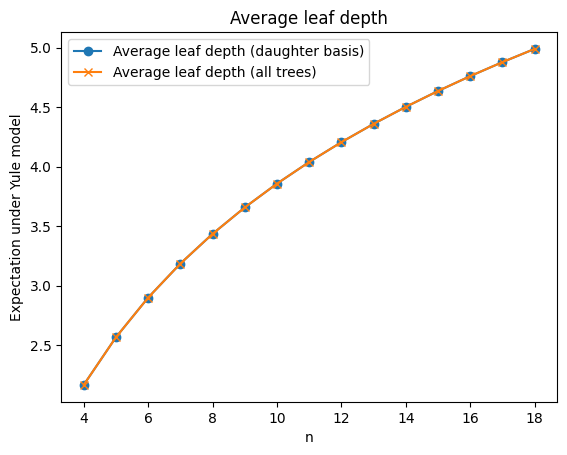

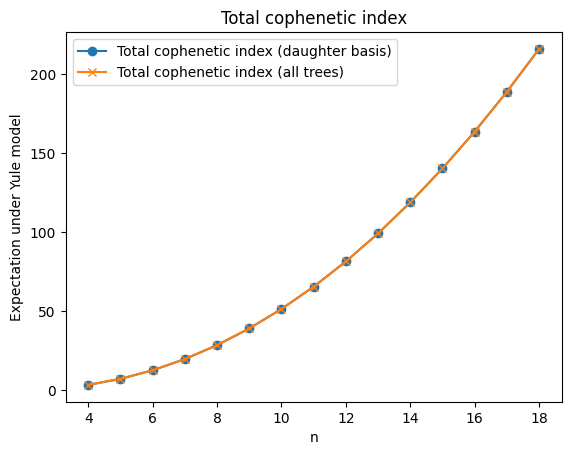

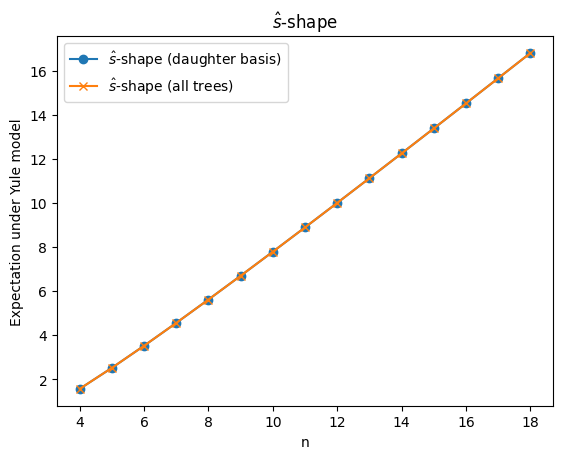

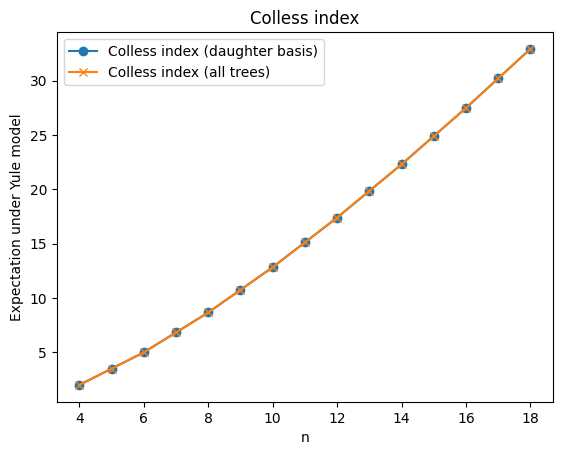

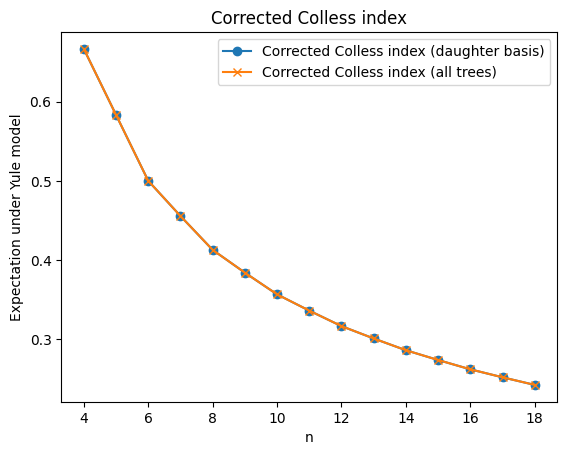

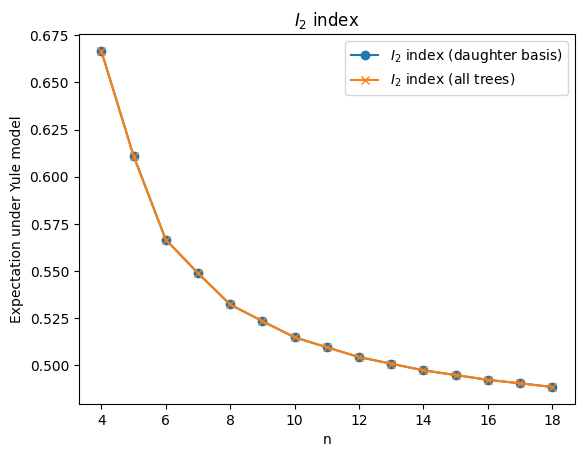

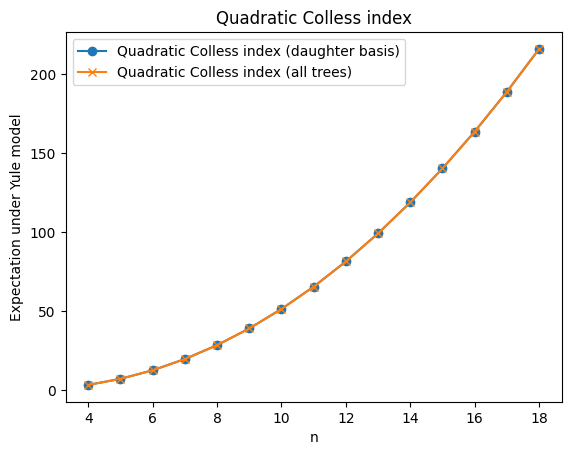

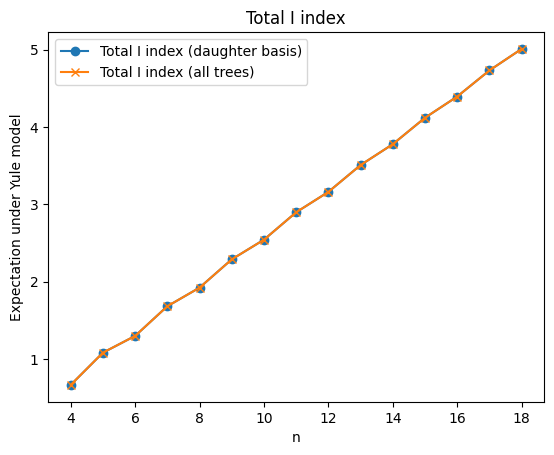

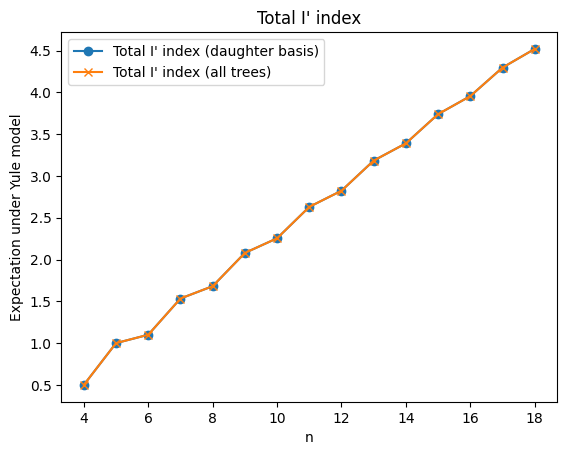

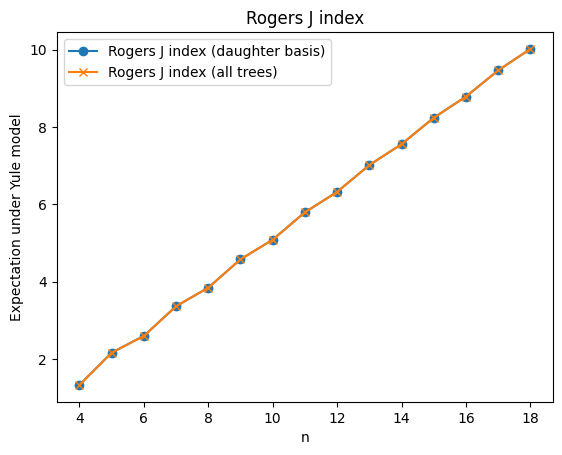

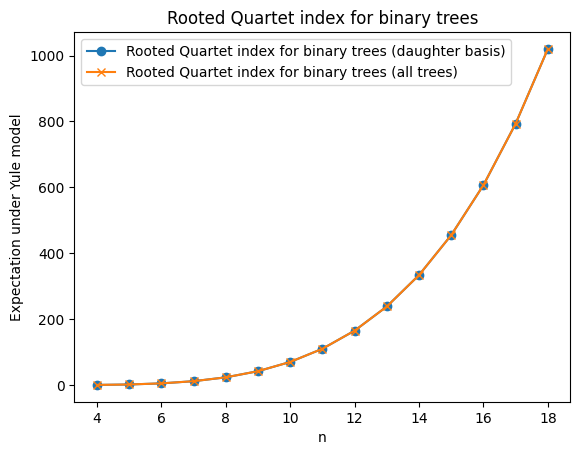

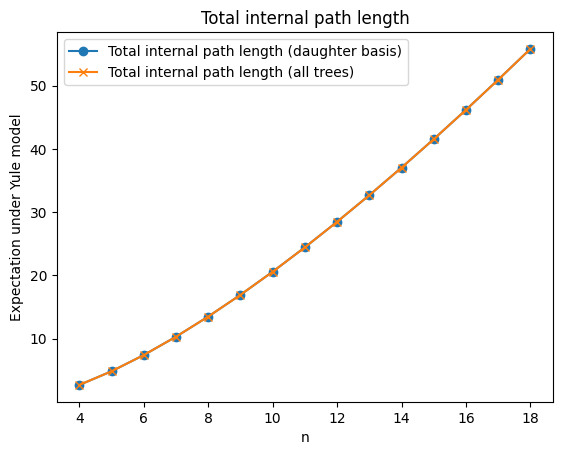

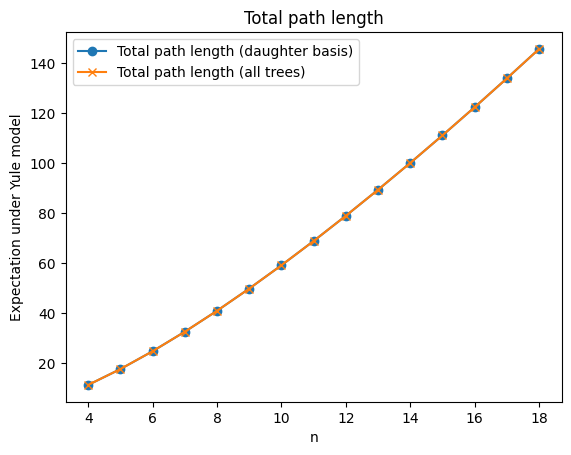

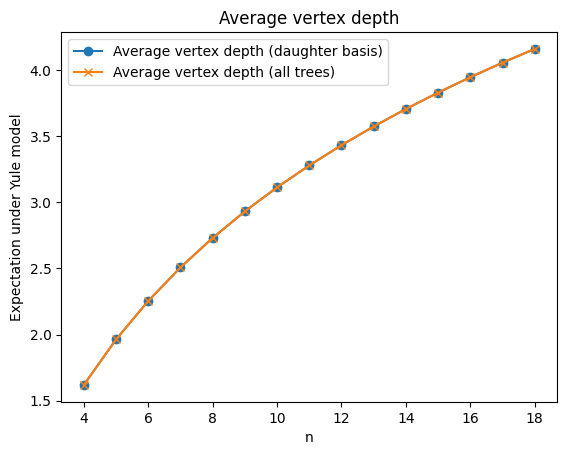

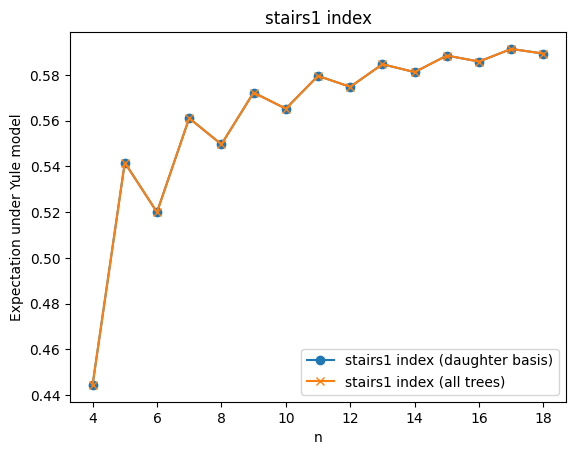

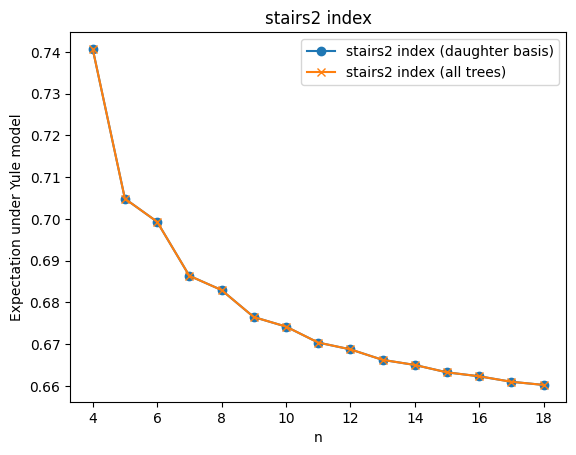

In [9]:
# Plot both methods together
for i, label in enumerate(labels):
    plt.plot(N, mean[:, i], label=label + ' (daughter basis)', marker='o')
    plt.plot(N, mean_all_trees[:, i], label=label + ' (all trees)', marker='x')
    plt.xlabel('n')
    plt.ylabel('Expectation under Yule model')
    plt.title(label)
    plt.legend()
    plt.show()

In [19]:
# Let's see what the differences are between the two methods
diff = np.max(np.abs(mean - mean_all_trees), axis=0)
max_diff_loc = np.argmax(diff)
labels[max_diff_loc], diff[max_diff_loc]

('Rooted Quartet index for binary trees', np.float64(1.1368683772161603e-13))

This makes sense, because it has the largest magnitude, so the error from numerical methods will be slightly higher